# 카드 거래 이상 탐지 (FDS 미니 프로젝트)

카드 거래 기록으로 사기 거래를 잡는 모델을 만들고, 네 가지를 비교

| 단계 | 질문 |
|---|---|
| 1. 불균형 처리 | 사기가 0.5%밖에 없을 때 무엇을 바꿔야 잡히나 |
| 2. 비지도 이상 탐지 | 라벨 없이 정상 거래만 보고도 사기를 찾을 수 있나 |
| 3. 행동 시퀀스 피처 | 카드별 과거 거래 흐름을 넣으면 얼마나 좋아지나 |
| 4. 시간에 따른 성능 | 학습 이후 시간이 지나면 성능이 떨어지나 |

데이터: Kaggle `kartik2112/fraud-detection` (Sparkov로 생성한 시뮬레이션 카드 거래, 2019.01~2020.12)
- 학습 파일 약 130만 건(2019.01 - 2020.06), 테스트 파일 약 55만 건(2020.06 - 2020.12)

In [1]:
import os, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
C1, C2, C3, C4 = 'lightcoral', 'khaki', 'darkseagreen', 'cornflowerblue'

## 0. 데이터 받기

`kagglehub`

In [2]:
def find_data():
    if os.path.exists('fraudTrain.csv') and os.path.exists('fraudTest.csv'):
        return '.'
    import kagglehub
    return kagglehub.dataset_download('kartik2112/fraud-detection')

DATA = find_data()
cols = ['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'gender',
        'lat', 'long', 'city_pop', 'dob', 'merch_lat', 'merch_long', 'is_fraud']
tr_raw = pd.read_csv(f'{DATA}/fraudTrain.csv', usecols=cols)
te_raw = pd.read_csv(f'{DATA}/fraudTest.csv', usecols=cols)
tr_raw['split'] = 'train'
te_raw['split'] = 'test'
df = pd.concat([tr_raw, te_raw], ignore_index=True)
df['ts'] = pd.to_datetime(df['trans_date_trans_time'])
df = df.sort_values(['ts']).reset_index(drop=True)

pd.DataFrame({
    'rows': df.groupby('split').size(),
    'fraud_rate(%)': (df.groupby('split')['is_fraud'].mean() * 100).round(3),
    'start': df.groupby('split')['ts'].min(),
    'end': df.groupby('split')['ts'].max(),
    'cards': df.groupby('split')['cc_num'].nunique(),
})

Using Colab cache for faster access to the 'fraud-detection' dataset.


,rows,fraud_rate(%),start,end,cards
split,,,,,
test,555719,0.386,2020-06-21 12:14:25,2020-12-31 23:59:34,924
train,1296675,0.579,2019-01-01 00:00:18,2020-06-21 12:13:37,983


## 1. 데이터 살펴보기

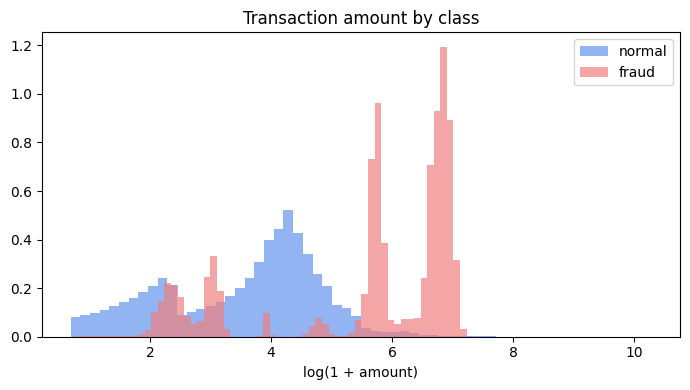

In [3]:
plt.figure(figsize=(7, 4))
plt.hist(np.log1p(df.loc[df.is_fraud == 0, 'amt']), bins=60, alpha=.7, density=True, color=C4, label='normal')
plt.hist(np.log1p(df.loc[df.is_fraud == 1, 'amt']), bins=60, alpha=.7, density=True, color=C1, label='fraud')
plt.xlabel('log(1 + amount)')
plt.title('Transaction amount by class')
plt.legend()
plt.tight_layout()
plt.show()

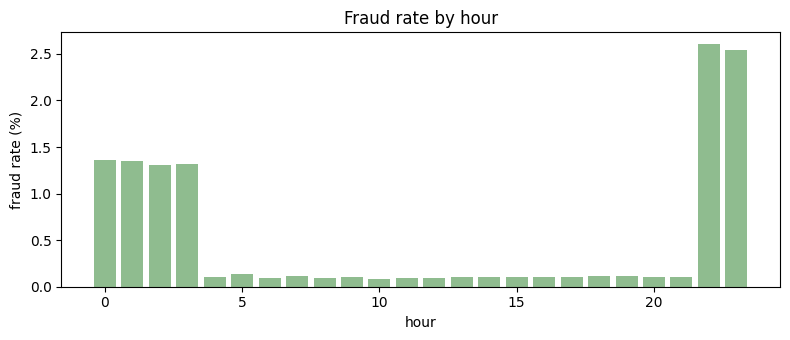

In [4]:
hour_rate = df.groupby(df.ts.dt.hour)['is_fraud'].mean() * 100
plt.figure(figsize=(8, 3.5))
plt.bar(hour_rate.index, hour_rate.values, color=C3)
plt.xlabel('hour')
plt.ylabel('fraud rate (%)')
plt.title('Fraud rate by hour')
plt.tight_layout()
plt.show()

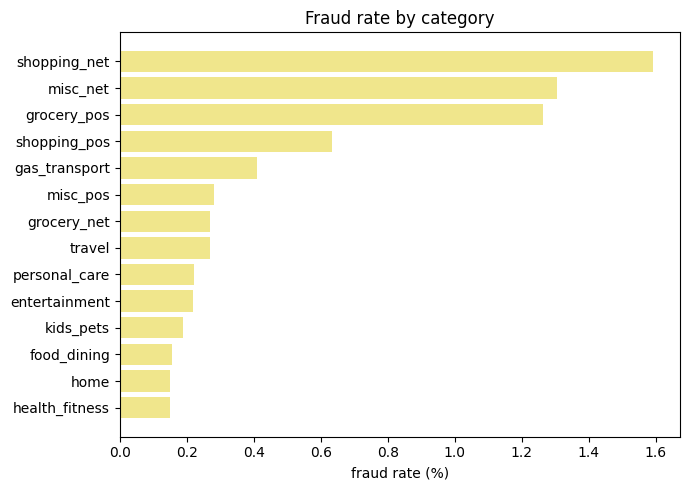

In [5]:
cat_rate = (df.groupby('category')['is_fraud'].mean() * 100).sort_values()
plt.figure(figsize=(7, 5))
plt.barh(cat_rate.index, cat_rate.values, color=C2)
plt.xlabel('fraud rate (%)')
plt.title('Fraud rate by category')
plt.tight_layout()
plt.show()

- **PR-AUC (average precision)**: 사기를 위로 얼마나 잘 올리는지. 불균형 데이터의 기본 지표
- **Recall@P80**: 경보의 80%가 진짜 사기가 되도록 기준을 잡았을 때 사기를 몇 % 잡는지

## 2. 거래 단위 피처

한 건의 거래만 보고 알 수 있는 정보만 사용

In [6]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df['log_amt'] = np.log1p(df['amt'])
df['hour'] = df.ts.dt.hour
df['dow'] = df.ts.dt.dayofweek
df['night'] = df['hour'].isin([22, 23, 0, 1, 2, 3]).astype(int)
df['age'] = (df.ts - pd.to_datetime(df['dob'])).dt.days / 365.25
df['dist_km'] = haversine(df.lat, df.long, df.merch_lat, df.merch_long)
df['log_city_pop'] = np.log1p(df['city_pop'])
df['is_male'] = (df['gender'] == 'M').astype(int)
df['cat_code'] = df['category'].astype('category').cat.codes

BASE = ['log_amt', 'hour', 'dow', 'night', 'age', 'dist_km', 'log_city_pop', 'is_male', 'cat_code']
df[BASE].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
log_amt,1852394.0,3.53,1.29,0.69,2.36,3.88,4.43,10.27
hour,1852394.0,12.81,6.82,0.00,7.00,14.00,19.00,23.00
dow,1852394.0,2.97,2.20,0.00,1.00,3.00,5.00,6.00
night,1852394.0,0.23,0.42,0.00,0.00,0.00,0.00,1.00
age,1852394.0,46.26,17.41,13.92,32.89,44.24,57.31,96.17
dist_km,1852394.0,76.11,29.12,0.02,55.32,78.22,98.51,152.12
log_city_pop,1852394.0,8.36,2.45,3.18,6.61,7.80,9.92,14.88
is_male,1852394.0,0.45,0.50,0.00,0.00,0.00,1.00,1.00
cat_code,1852394.0,6.23,3.91,0.00,3.00,6.00,10.00,13.00


### 학습 / 검증 / 테스트 나누기

- 학습: train 파일 중 마지막 2개월 전까지
- 검증: train 파일 마지막 2개월 (임계값 고르는 용도)
- 테스트: test 파일 전체 (학습 이후 6개월)

In [7]:
tr_end = df.loc[df.split == 'train', 'ts'].max()
va_start = tr_end - pd.DateOffset(months=2)

is_tr = (df.split == 'train') & (df.ts < va_start)
is_va = (df.split == 'train') & (df.ts >= va_start)
is_te = df.split == 'test'

y = df['is_fraud'].values
pd.DataFrame({
    'rows': [is_tr.sum(), is_va.sum(), is_te.sum()],
    'fraud': [y[is_tr].sum(), y[is_va].sum(), y[is_te].sum()],
}, index=['train', 'valid', 'test'])

,rows,fraud
train,1143809,6552
valid,152866,954
test,555719,2145


In [8]:
def recall_at_precision(y_true, score, p=0.8):
    prec, rec, _ = precision_recall_curve(y_true, score)
    ok = rec[prec >= p]
    return ok.max() if len(ok) else 0.0

def evaluate(name, score_te):
    return {'model': name,
            'PR-AUC': average_precision_score(y[is_te], score_te),
            'ROC-AUC': roc_auc_score(y[is_te], score_te),
            'Recall@P80': recall_at_precision(y[is_te], score_te)}

results = []

## 3. 불균형 처리 비교

같은 모델(Gradient Boosting)에 불균형 처리 방법만 변형

| 방법 | 내용 |
|---|---|
| 그대로 | 아무것도 안 함 |
| 클래스 가중치 | 사기 샘플의 손실을 크게 줌 |
| 언더샘플링 | 정상 거래를 줄여서 사기:정상 = 1:10으로 맞춤 |

In [9]:
def gbm():
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
                                          min_samples_leaf=50, l2_regularization=1.0,
                                          early_stopping=False, random_state=SEED)

X_tr, X_te = df.loc[is_tr, BASE], df.loc[is_te, BASE]
y_tr = y[is_tr]

m_plain = gbm().fit(X_tr, y_tr)
results.append(evaluate('GBM (no handling)', m_plain.predict_proba(X_te)[:, 1]))

w = np.where(y_tr == 1, (y_tr == 0).sum() / (y_tr == 1).sum(), 1.0)
m_weight = gbm().fit(X_tr, y_tr, sample_weight=w)
results.append(evaluate('GBM (class weight)', m_weight.predict_proba(X_te)[:, 1]))

rng = np.random.default_rng(SEED)
pos = np.where(y_tr == 1)[0]
neg = rng.choice(np.where(y_tr == 0)[0], size=min(len(pos) * 10, (y_tr == 0).sum()), replace=False)
idx = np.concatenate([pos, neg])
m_under = gbm().fit(X_tr.iloc[idx], y_tr[idx])
results.append(evaluate('GBM (undersample 1:10)', m_under.predict_proba(X_te)[:, 1]))

pd.DataFrame(results).set_index('model').round(4)

,PR-AUC,ROC-AUC,Recall@P80
model,,,
GBM (no handling),0.8773,0.9969,0.8149
GBM (class weight),0.8725,0.9977,0.7949
GBM (undersample 1:10),0.8772,0.9976,0.8005


보통 PR-AUC는 셋이 크게 다르지 않고, **점수 순서(랭킹)보다 확률값의 크기**가 달라짐

가중치나 언더샘플링은 확률을 위로 밀어 올려서 기본 임계값 0.5에서 더 많이 잡히게 만드는 효과가 큼

## 4. 비지도 이상 탐지

라벨을 안 쓰고 **정상 거래만** 학습해서, 정상과 많이 다른 거래를 이상으로 감지

사기 라벨이 늦게 들어오거나 새로운 수법이 나올 때 쓰는 방식

- Isolation Forest: 적은 분할로 고립되는 점을 이상으로 봄
- 오토인코더: 정상 거래를 압축했다 복원하도록 학습 → 복원이 잘 안 되는(오차가 큰) 거래를 이상으로 봄

In [10]:
AE_FEATS = BASE
scaler = StandardScaler().fit(df.loc[is_tr & (df.is_fraud == 0), AE_FEATS])
Z = scaler.transform(df[AE_FEATS]).astype(np.float32)

normal_tr = np.where(is_tr & (df.is_fraud == 0))[0]
sub = np.random.default_rng(SEED).choice(normal_tr, size=min(200_000, len(normal_tr)), replace=False)

iso = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1).fit(Z[sub])
results.append(evaluate('Isolation Forest (unsupervised)', -iso.score_samples(Z[is_te.values])))

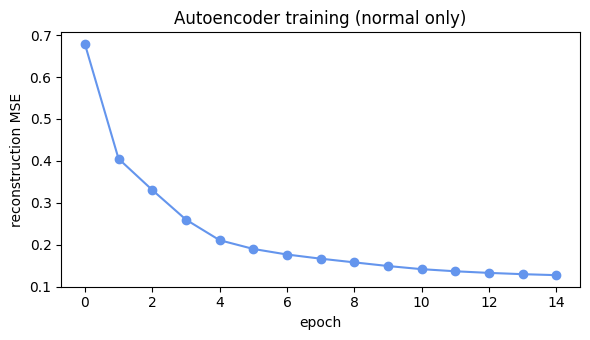

In [11]:
class AE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(d, 32), nn.ReLU(), nn.Linear(32, 4))
        self.dec = nn.Sequential(nn.Linear(4, 32), nn.ReLU(), nn.Linear(32, d))
    def forward(self, x):
        return self.dec(self.enc(x))

ae = AE(Z.shape[1]).to(device)
opt = torch.optim.Adam(ae.parameters(), lr=1e-3)
X_ae = torch.tensor(Z[sub])
loss_hist = []
for ep in range(15):
    perm = torch.randperm(len(X_ae))
    tot = 0
    for i in range(0, len(perm), 1024):
        xb = X_ae[perm[i:i + 1024]].to(device)
        loss = ((ae(xb) - xb) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * len(xb)
    loss_hist.append(tot / len(X_ae))

plt.figure(figsize=(6, 3.5))
plt.plot(loss_hist, color=C4, marker='o')
plt.xlabel('epoch')
plt.ylabel('reconstruction MSE')
plt.title('Autoencoder training (normal only)')
plt.tight_layout()
plt.show()

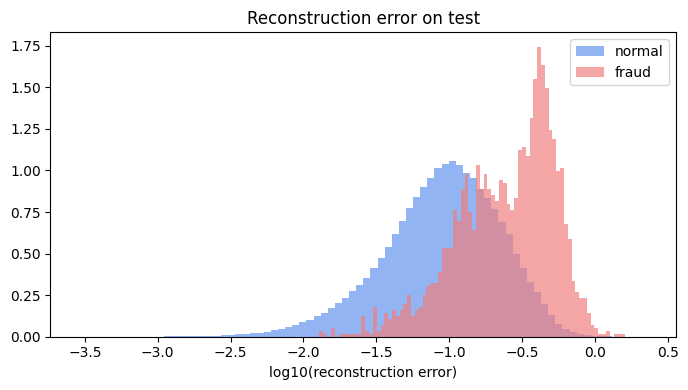

,PR-AUC,ROC-AUC,Recall@P80
model,,,
GBM (no handling),0.8773,0.9969,0.8149
GBM (class weight),0.8725,0.9977,0.7949
GBM (undersample 1:10),0.8772,0.9976,0.8005
Isolation Forest (unsupervised),0.0315,0.8598,0.0000
Autoencoder (unsupervised),0.0249,0.8037,0.0000


In [12]:
@torch.no_grad()
def recon_error(X):
    ae.eval()
    out = []
    for i in range(0, len(X), 8192):
        xb = torch.tensor(X[i:i + 8192]).to(device)
        out.append(((ae(xb) - xb) ** 2).mean(1).cpu().numpy())
    return np.concatenate(out)

err_te = recon_error(Z[is_te.values])
results.append(evaluate('Autoencoder (unsupervised)', err_te))

plt.figure(figsize=(7, 4))
plt.hist(np.log10(err_te[y[is_te] == 0] + 1e-6), bins=80, alpha=.7, density=True, color=C4, label='normal')
plt.hist(np.log10(err_te[y[is_te] == 1] + 1e-6), bins=80, alpha=.7, density=True, color=C1, label='fraud')
plt.xlabel('log10(reconstruction error)')
plt.title('Reconstruction error on test')
plt.legend()
plt.tight_layout()
plt.show()

pd.DataFrame(results).set_index('model').round(4)

비지도 방식은 라벨을 쓴 모델보다 대체로 낮은 성능

대신 "라벨 없이 어디까지 되는지"가 기준선이 되고, 새로운 유형의 사기를 잡는 보조 수단으로 사용

## 5. 행동 시퀀스 피처

카드별로 거래를 시간순으로 놓고, **그 거래 이전 기록만** 써서 피처를 생성 (현재·미래 거래를 쓰면 정보 누수)

| 피처 | 의미 |
|---|---|
| secs_since_prev | 직전 거래와 시간 간격 |
| amt_ratio_mean | 이번 금액 / 이 카드의 과거 평균 금액 |
| amt_z | 과거 금액 분포 대비 몇 표준편차인지 |
| n_1h, n_24h | 최근 1시간·24시간 거래 수 |
| amt_24h | 최근 24시간 사용 금액 합 |
| new_category | 이 카드가 처음 쓰는 업종인지 |
| card_txn_idx | 이 카드의 몇 번째 거래인지 |

In [13]:
t0 = time.time()
df = df.sort_values(['cc_num', 'ts']).reset_index(drop=True)
g = df.groupby('cc_num', sort=False)

df['secs_since_prev'] = g['ts'].diff().dt.total_seconds().fillna(1e7)
df['card_txn_idx'] = g.cumcount()

past_sum = g['amt'].cumsum() - df['amt']
past_sq = g['amt'].transform(lambda s: (s ** 2).cumsum()) - df['amt'] ** 2
n_past = df['card_txn_idx'].replace(0, np.nan)
past_mean = past_sum / n_past
past_std = np.sqrt((past_sq / n_past - past_mean ** 2).clip(lower=0))
df['amt_ratio_mean'] = (df['amt'] / past_mean).fillna(1.0)
df['amt_z'] = ((df['amt'] - past_mean) / (past_std + 1)).fillna(0.0)

def window_feats(sub):
    s = sub.set_index('ts')['amt']
    return pd.DataFrame({
        'n_1h': s.rolling('1h', closed='left').count().values,
        'n_24h': s.rolling('24h', closed='left').count().values,
        'amt_24h': s.rolling('24h', closed='left').sum().values,
    }, index=sub.index)

wf = pd.concat([window_feats(sub) for _, sub in g[['ts', 'amt']]])
df[['n_1h', 'n_24h', 'amt_24h']] = wf.loc[df.index].fillna(0).values

df['new_category'] = (~df.duplicated(['cc_num', 'category'])).astype(int)

df = df.sort_values('ts').reset_index(drop=True)
is_tr = (df.split == 'train') & (df.ts < va_start)
is_va = (df.split == 'train') & (df.ts >= va_start)
is_te = df.split == 'test'
y = df['is_fraud'].values

SEQ = ['secs_since_prev', 'amt_ratio_mean', 'amt_z', 'n_1h', 'n_24h', 'amt_24h', 'new_category', 'card_txn_idx']
f'{time.time() - t0:.1f}s'

'11.3s'

In [14]:
FEATS = BASE + SEQ
y_tr = y[is_tr]
w = np.where(y_tr == 1, (y_tr == 0).sum() / (y_tr == 1).sum(), 1.0)
m_seq = gbm().fit(df.loc[is_tr, FEATS], y_tr, sample_weight=w)
score_seq_te = m_seq.predict_proba(df.loc[is_te, FEATS])[:, 1]
results.append(evaluate('GBM + sequence features', score_seq_te))

# 비교용으로 정렬이 바뀐 df 기준으로 거래 단위 모델도 다시 계산
m_base = gbm().fit(df.loc[is_tr, BASE], y_tr, sample_weight=w)
score_base_te = m_base.predict_proba(df.loc[is_te, BASE])[:, 1]

res = pd.DataFrame(results).set_index('model').round(4)
res

,PR-AUC,ROC-AUC,Recall@P80
model,,,
GBM (no handling),0.8773,0.9969,0.8149
GBM (class weight),0.8725,0.9977,0.7949
GBM (undersample 1:10),0.8772,0.9976,0.8005
Isolation Forest (unsupervised),0.0315,0.8598,0.0000
Autoencoder (unsupervised),0.0249,0.8037,0.0000
GBM + sequence features,0.9691,0.9994,0.9580


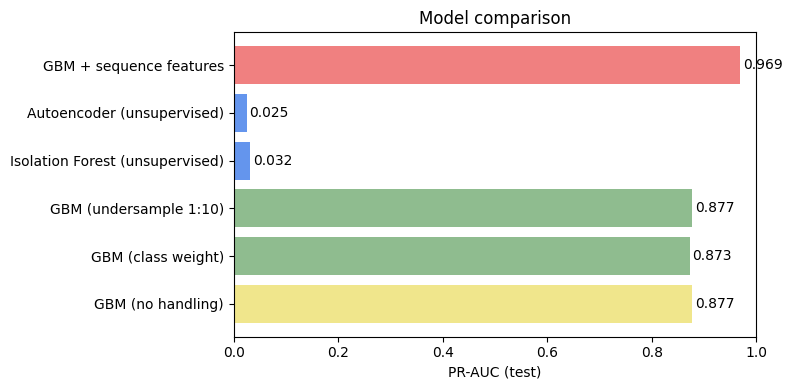

In [15]:
plt.figure(figsize=(8, 4))
colors = [C2, C3, C3, C4, C4, C1]
plt.barh(res.index, res['PR-AUC'], color=colors[:len(res)])
for i, v in enumerate(res['PR-AUC']):
    plt.text(v + 0.005, i, f'{v:.3f}', va='center')
plt.xlabel('PR-AUC (test)')
plt.title('Model comparison')
plt.xlim(0, min(1.0, res['PR-AUC'].max() + 0.12))
plt.tight_layout()
plt.show()

### 어떤 피처가 효과가 있었나 (순열 중요도)

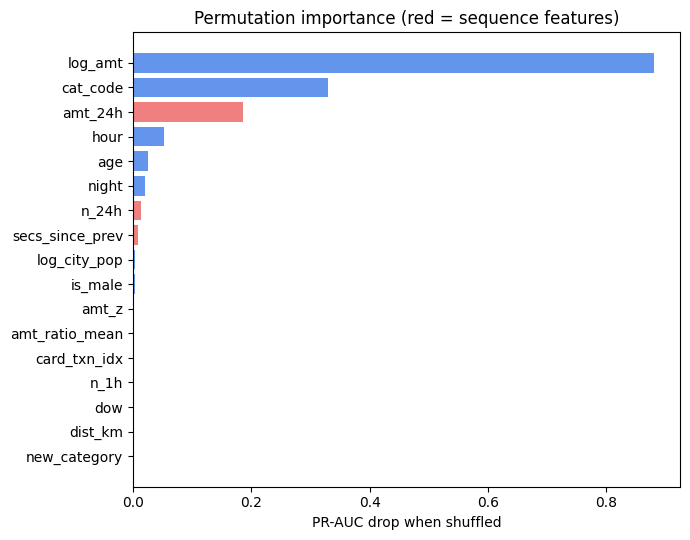

In [16]:
from sklearn.inspection import permutation_importance

samp = df.loc[is_va].sample(min(100_000, is_va.sum()), random_state=SEED)
pi = permutation_importance(m_seq, samp[FEATS], samp['is_fraud'], scoring='average_precision',
                            n_repeats=3, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values()

plt.figure(figsize=(7, 5.5))
plt.barh(imp.index, imp.values, color=[C1 if f in SEQ else C4 for f in imp.index])
plt.xlabel('PR-AUC drop when shuffled')
plt.title('Permutation importance (red = sequence features)')
plt.tight_layout()
plt.show()

## 6. 임계값 정하기

이상 탐지 기준 책정 - **검증 데이터**로 정한 뒤 테스트에 그대로 적용

여기서는 검증 데이터에서 정밀도 80%를 넘는 가장 낮은 임계값을 선택 (경보 10개 중 8개가 실제 사기)

In [17]:
score_va = m_seq.predict_proba(df.loc[is_va, FEATS])[:, 1]
prec, rec, thr = precision_recall_curve(y[is_va], score_va)
ok = np.where(prec[:-1] >= 0.8)[0]
th = thr[ok[0]] if len(ok) else 0.5

pred_te = score_seq_te >= th
y_te = y[is_te]
tp = int((pred_te & (y_te == 1)).sum())
fp = int((pred_te & (y_te == 0)).sum())
fn = int((~pred_te & (y_te == 1)).sum())

pd.Series({
    'threshold (from valid)': float(f'{th:.6g}'),
    'alerts': int(pred_te.sum()),
    'caught fraud (TP)': tp,
    'false alarms (FP)': fp,
    'missed fraud (FN)': fn,
    'precision': round(tp / max(tp + fp, 1), 3),
    'recall': round(tp / max(tp + fn, 1), 3),
    'caught fraud amount': round(float(df.loc[is_te, 'amt'][pred_te & (y_te == 1)].sum()), 0),
    'missed fraud amount': round(float(df.loc[is_te, 'amt'][~pred_te & (y_te == 1)].sum()), 0),
})

,0
threshold (from valid),5.425800e-01
alerts,2.873000e+03
caught fraud (TP),2.073000e+03
false alarms (FP),8.000000e+02
missed fraud (FN),7.200000e+01
precision,7.220000e-01
recall,9.660000e-01
caught fraud amount,1.119480e+06
missed fraud amount,1.384500e+04


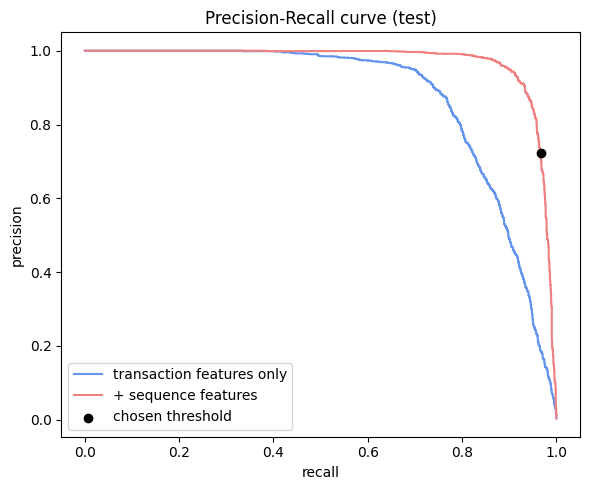

In [18]:
p_te, r_te, _ = precision_recall_curve(y_te, score_seq_te)
p_b, r_b, _ = precision_recall_curve(y_te, score_base_te)

plt.figure(figsize=(6, 5))
plt.plot(r_b, p_b, color=C4, label='transaction features only')
plt.plot(r_te, p_te, color=C1, label='+ sequence features')
plt.scatter([tp / max(tp + fn, 1)], [tp / max(tp + fp, 1)], color='black', zorder=5, label='chosen threshold')
plt.xlabel('recall')
plt.ylabel('precision')
plt.title('Precision-Recall curve (test)')
plt.legend()
plt.tight_layout()
plt.show()

## 7. 시간이 지나면 성능이 떨어지나

학습은 한 번만 하고, 테스트 기간을 월별로 잘라 성능을 확인

사기 수법이나 고객 행동이 바뀌면(드리프트) 뒤로 갈수록 성능 저하

같은 기간에 학습 데이터를 **최근 6개월만** 쓴 모델도 비교

오래된 데이터가 오히려 방해가 되는지 보는 실험

In [19]:
recent = (df.split == 'train') & (df.ts >= tr_end - pd.DateOffset(months=6))
yr = y[recent]
wr = np.where(yr == 1, (yr == 0).sum() / max((yr == 1).sum(), 1), 1.0)
m_recent = gbm().fit(df.loc[recent, FEATS], yr, sample_weight=wr)

te = df.loc[is_te, ['ts', 'is_fraud']].copy()
te['s_all'] = score_seq_te
te['s_recent'] = m_recent.predict_proba(df.loc[is_te, FEATS])[:, 1]
te['month'] = te.ts.dt.to_period('M').astype(str)

monthly = te.groupby('month').apply(lambda d: pd.Series({
    'n_fraud': int(d.is_fraud.sum()),
    'PR-AUC (all history)': average_precision_score(d.is_fraud, d.s_all) if d.is_fraud.sum() else np.nan,
    'PR-AUC (recent 6m)': average_precision_score(d.is_fraud, d.s_recent) if d.is_fraud.sum() else np.nan,
}), include_groups=False)
monthly.round(4)

,n_fraud,PR-AUC (all history),PR-AUC (recent 6m)
month,,,
2020-06,133.0,0.9785,0.9687
2020-07,321.0,0.9563,0.9423
2020-08,415.0,0.9759,0.9694
2020-09,340.0,0.9766,0.9676
2020-10,384.0,0.9728,0.9691
2020-11,294.0,0.9708,0.9706
2020-12,258.0,0.9512,0.9318


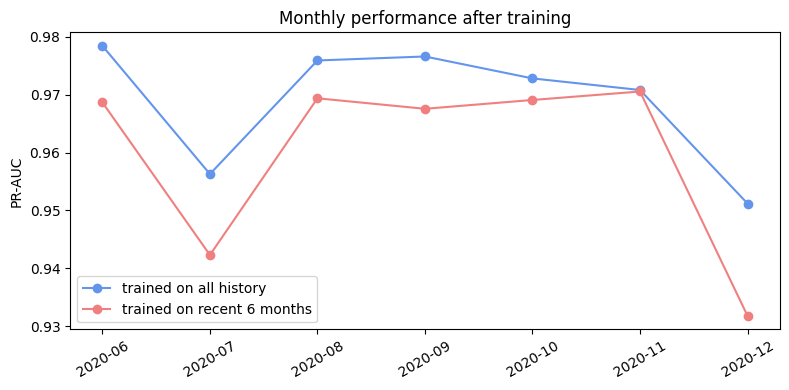

In [20]:
plt.figure(figsize=(8, 4))
plt.plot(monthly.index, monthly['PR-AUC (all history)'], marker='o', color=C4, label='trained on all history')
plt.plot(monthly.index, monthly['PR-AUC (recent 6m)'], marker='o', color=C1, label='trained on recent 6 months')
plt.ylabel('PR-AUC')
plt.title('Monthly performance after training')
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

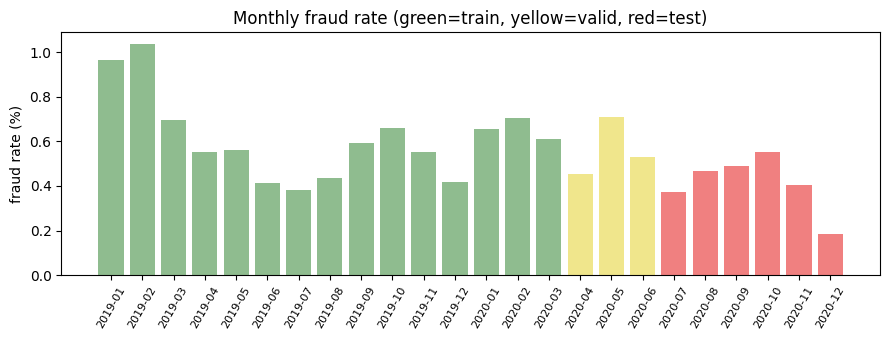

In [21]:
fr = df.groupby(df.ts.dt.to_period('M').astype(str))['is_fraud'].mean() * 100
plt.figure(figsize=(9, 3.5))
plt.bar(fr.index, fr.values, color=[C3 if m < str(va_start.to_period('M')) else (C2 if m <= str(tr_end.to_period('M')) else C1) for m in fr.index])
plt.ylabel('fraud rate (%)')
plt.title('Monthly fraud rate (green=train, yellow=valid, red=test)')
plt.xticks(rotation=60, fontsize=8)
plt.tight_layout()
plt.show()

## 8. 정리

| 질문 | 확인할 것 |
|---|---|
| 불균형 처리 | 가중치·언더샘플링이 PR-AUC(랭킹)보다 확률값·기본 임계값 결과를 주로 바꾸는지 |
| 비지도 | 라벨 없이 어디까지 되는지, 지도학습과 차이가 얼마인지 |
| 시퀀스 피처 | 카드별 과거 행동과 비교하는 피처가 얼마나 올려주는지, 어떤 피처가 컸는지 |
| 임계값 | 정밀도 80% 기준에서 놓치는 사기와 오탐 규모 |
| 시간 | 월별로 성능이 떨어지는지, 최근 데이터만 쓴 모델이 나은지 |